In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch   
import torch.nn as nn
from torch.autograd import Variable
import torch.nn.functional as F

import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset

전체적인 구조
1. dataloder준비
2. model 준비
3. 학습

In [2]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

Using device: mps


In [3]:
train_dataset = torchvision.datasets.FashionMNIST(".", download=True, transform=transforms.Compose([transforms.ToTensor()]))
test_dataset = torchvision.datasets.FashionMNIST(".", download=True, train=False, transform=transforms.Compose([transforms.ToTensor()]))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=100)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=100)

100%|██████████| 26.4M/26.4M [00:35<00:00, 751kB/s] 
100%|██████████| 29.5k/29.5k [00:00<00:00, 99.1kB/s]
100%|██████████| 4.42M/4.42M [00:13<00:00, 326kB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 6.19MB/s]


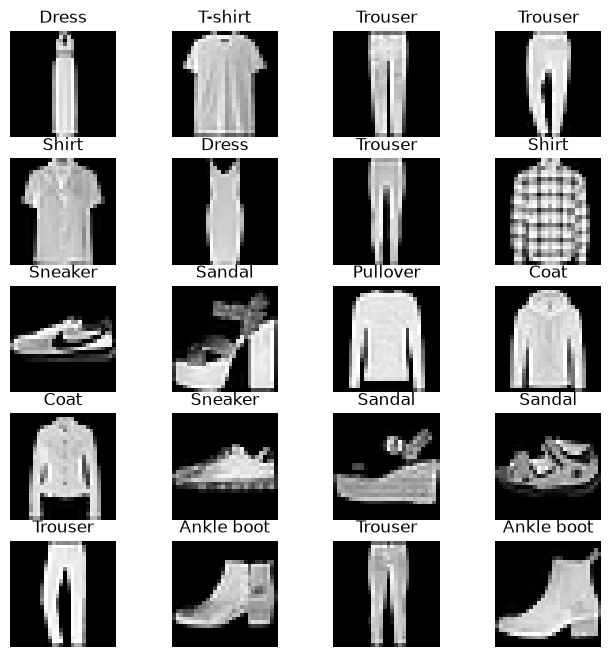

In [7]:
labels_map = {
    0: "T-shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}
fig = plt.figure(figsize=(8, 8))
columns = 4
rows = 5
for i in range(1, columns*rows + 1):
    img_xy = np.random.randint(len(train_dataset))
    img = train_dataset[img_xy][0][0,:,:]
    fig.add_subplot(rows, columns, i)
    plt.title(labels_map[train_dataset[img_xy][1]])
    plt.axis("off")
    plt.imshow(img, cmap='gray')
plt.show()

In [8]:
class FashionDNN(nn.Module):
    def __init__(self):
        super(FashionDNN, self).__init__()
        self.fc1 = nn.Linear(784, 256)
        self.drop = nn.Dropout(0.25)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 10)

    def forward(self, x):
        x = x.view(-1, 784)
        x = F.relu(self.fc1(x))
        x = self.drop(x)
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [9]:
learning_rate = 0.001
model = FashionDNN()
model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [10]:
num_epochs = 5
count = 0
loss_list = []
iteration_list = []
accuracy_list = []

predicted_list = []
labels_list = []

In [11]:
for epoch in range(num_epochs):
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        train = Variable(images.view(100,1, 28,28))
        labels = Variable(labels)

        outputs = model(train)
        loss = criterion(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        count += 1

        if not count % 50:
            total = 0
            correct = 0
            for images, labels in test_loader:
                images = images.to(device)
                labels = labels.to(device)
                labels_list.append(labels)
                test = Variable(images.view(100,1, 28*28))
                outputs = model(test)
                predicted = torch.max(outputs.data, 1)[1].to(device)
                predicted_list.append(predicted)
                correct += (predicted == labels).sum()
                total += len(labels)

            accuracy = 100 * correct / total
            loss_list.append(loss.data)
            accuracy_list.append(accuracy)
            iteration_list.append(count)
        if not count % 500:
            print(f"Iteration: {count}, Loss: {loss.data}, Accuracy: {accuracy}%".format(count, loss.data, accuracy))

Iteration: 500, Loss: 0.618704080581665, Accuracy: 83.27999877929688%
Iteration: 1000, Loss: 0.4920632541179657, Accuracy: 84.47000122070312%
Iteration: 1500, Loss: 0.4006178677082062, Accuracy: 84.52999877929688%
Iteration: 2000, Loss: 0.380909264087677, Accuracy: 85.33999633789062%
Iteration: 2500, Loss: 0.23144978284835815, Accuracy: 86.29000091552734%
Iteration: 3000, Loss: 0.29515281319618225, Accuracy: 86.5999984741211%


In [ ]:
class FashionCNN(nn.Module):
    def __init__(self):
        self.layer1 = nn.sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        self.layer2 = nn.sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.fc1 = nn.Linear(64 *  * 7, 600)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.pool(x)
        x = x.view(-1, 32 * 7 * 7)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x